# 01 — EDA de la poblacion sintetica real generada
Solo desarrollo; la cohorte 2024 queda reservada.

In [1]:
from pathlib import Path
import sys, json
sys.dont_write_bytecode = True
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/sinteticos.py").is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from IPython.display import display, Image
from src.experimentos import seed_everything, holdout_indices, cv_indices, evaluate_cv, tune_grid


## Generacion y procedencia
Monte Carlo de eventos, semilla/configuracion versionadas. Si faltan archivos, generar con `save_population()`. Se verifica la huella antes de analizar. Datos ficticios, no estadisticas municipales. Snowflake no se ha utilizado.

In [2]:
from src.analisis import load_population, run_eda
frame, manifest = load_population()
print(json.dumps(manifest['quality'], indent=2))
print('OBT SHA-256:', manifest['hashes']['obt'])
del frame  # la EDA siguiente carga exclusivamente desarrollo

{
  "obligations": 12000,
  "events": 18988,
  "obt_rows": 12000,
  "class_counts": {
    "1": 6865,
    "0": 5135
  },
  "cohorts": {
    "2019": {
      "size": 2000,
      "mean": 0.5785
    },
    "2020": {
      "size": 2000,
      "mean": 0.5495
    },
    "2021": {
      "size": 2000,
      "mean": 0.549
    },
    "2022": {
      "size": 2000,
      "mean": 0.576
    },
    "2023": {
      "size": 2000,
      "mean": 0.578
    },
    "2024": {
      "size": 2000,
      "mean": 0.6015
    }
  },
  "missing": {
    "LOTE_ID": 0,
    "OBLIGACION_ID": 0,
    "ANIO_FISCAL": 0,
    "FECHA_EMISION_DECLARADA": 0,
    "TOTAL_CENT": 0,
    "IMPORTE_PRINCIPAL": 0,
    "TOTAL_OBLIGACION_DECLARADO": 0,
    "AVALUO_SIMULADO": 0,
    "AREA_M2": 438,
    "ZONA_SIMULADA": 0,
    "USO_PREDIO": 0,
    "CANAL_NOTIFICACION": 231,
    "PLAZO_DIAS_SIMULADO": 0,
    "DATA_CLASSIFICATION": 0,
    "GENERATOR_VERSION": 0
  },
  "event_types": {
    "PAGO": 18349,
    "REVERSO": 457,
    "ADMINISTRATIVO":

In [3]:
eda_report = run_eda()
print(json.dumps(eda_report, indent=2))
import pandas as pd
for name in ['descriptivos','completitud','outliers','spearman']:
    print(name)
    display(pd.read_csv(ROOT / 'docs/eda' / f'{name}.csv', index_col=0))

{
  "development_rows": 9510,
  "target_counts": {
    "0": 4146,
    "1": 5364
  },
  "positive_rate": 0.5640378548895899,
  "spearman_feature_target": {
    "TOTAL_OBLIGACION_DECLARADO": 0.006145107544449678,
    "AVALUO_SIMULADO": 0.006145648026840678,
    "AREA_M2": 0.008504998618667166,
    "PLAZO_DIAS_SIMULADO": -0.0001307564750549565
  },
  "findings": [
    {
      "evidence": "Asimetria del importe: 5.294; atipicos IQR: 682.",
      "consequence": "Evaluar log1p(importe) como feature de emision; conservar cola sin eliminar extremos por target."
    },
    {
      "evidence": "Area ausente en 367 filas de desarrollo; canal ausente en 190.",
      "consequence": "Imputar exclusivamente dentro de cada fold y admitir categoria faltante; no imputar globalmente."
    },
    {
      "evidence": "Fraccion target=1: 0.5640; correlacion Spearman avaluo/importe: 1.0000.",
      "consequence": "Usar ROC-AUC primaria y AP/F1/balanced accuracy secundarias; excluir avaluo redundante de esta 

,count,mean,std,min,25%,50%,75%,max,skew
TOTAL_OBLIGACION_DECLARADO,9510.0,54.078107,52.324666,12.94,25.340,38.105,63.3675,1098.16,5.293905
AVALUO_SIMULADO,9510.0,35065.144648,43603.911417,782.32,11113.905,21757.250,42803.1925,905130.76,5.293890
AREA_M2,9143.0,207.434760,205.929018,20.00,86.300,151.770,255.2250,3657.89,4.164554
PLAZO_DIAS_SIMULADO,9510.0,40.250789,11.676111,30.00,30.000,30.000,45.0000,60.00,0.616308


completitud


,dtype,missing,completeness
LOTE_ID,str,0,1.000000
OBLIGACION_ID,str,0,1.000000
ANIO_FISCAL,int64,0,1.000000
FECHA_EMISION_DECLARADA,"datetime64[us, UTC]",0,1.000000
TOTAL_CENT,int64,0,1.000000
IMPORTE_PRINCIPAL,float64,0,1.000000
TOTAL_OBLIGACION_DECLARADO,float64,0,1.000000
AVALUO_SIMULADO,float64,0,1.000000
AREA_M2,float64,367,0.961409
ZONA_SIMULADA,str,0,1.000000


outliers


,feature,iqr_lower,iqr_upper,iqr_outliers,abs_z_gt_3
0,TOTAL_OBLIGACION_DECLARADO,-31.70125,120.40875,682,165
1,AVALUO_SIMULADO,-36420.02625,90337.12375,682,165
2,AREA_M2,-167.08750,508.61250,573,159
3,PLAZO_DIAS_SIMULADO,7.50000,67.50000,0,0


spearman


,TOTAL_OBLIGACION_DECLARADO,AVALUO_SIMULADO,AREA_M2,PLAZO_DIAS_SIMULADO
TOTAL_OBLIGACION_DECLARADO,1.000000,1.000000,0.803627,-0.013746
AVALUO_SIMULADO,1.000000,1.000000,0.803629,-0.013752
AREA_M2,0.803627,0.803629,1.000000,-0.012218
PLAZO_DIAS_SIMULADO,-0.013746,-0.013752,-0.012218,1.000000


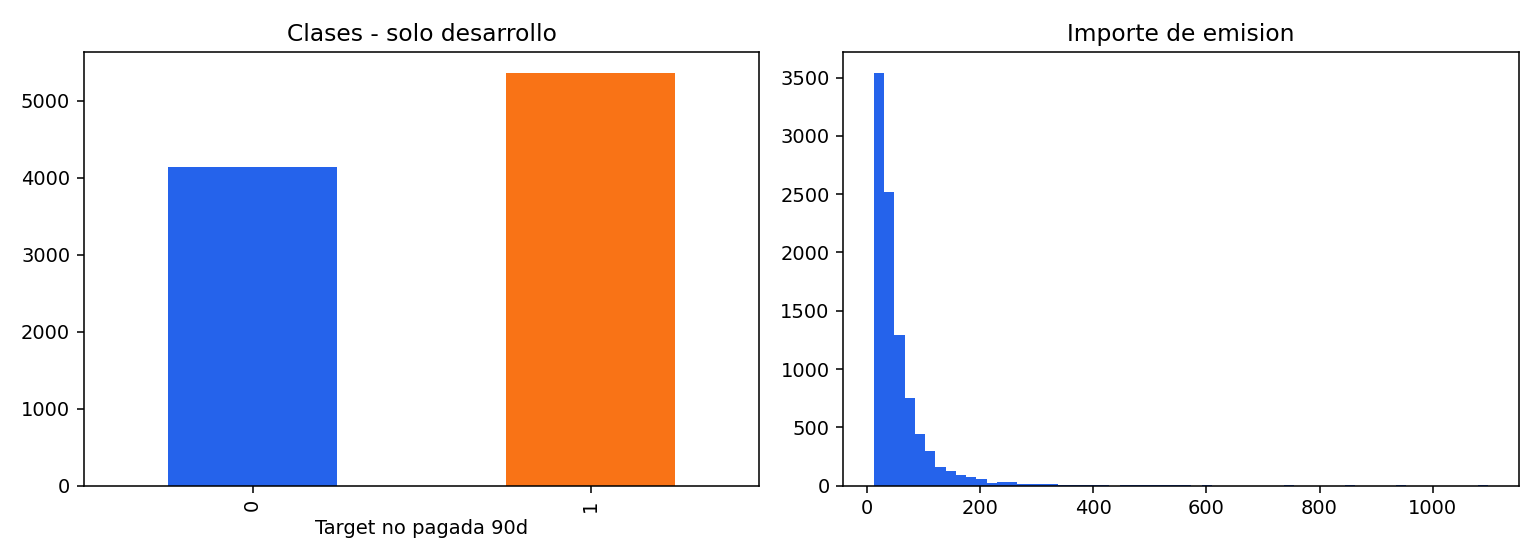

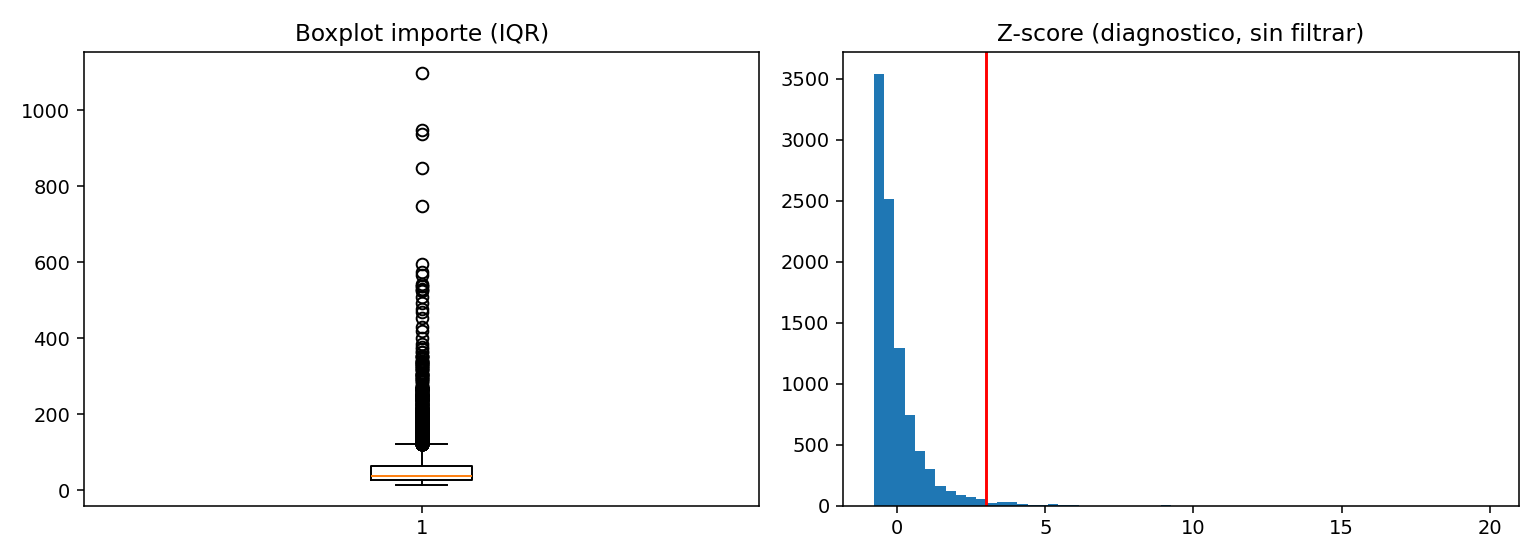

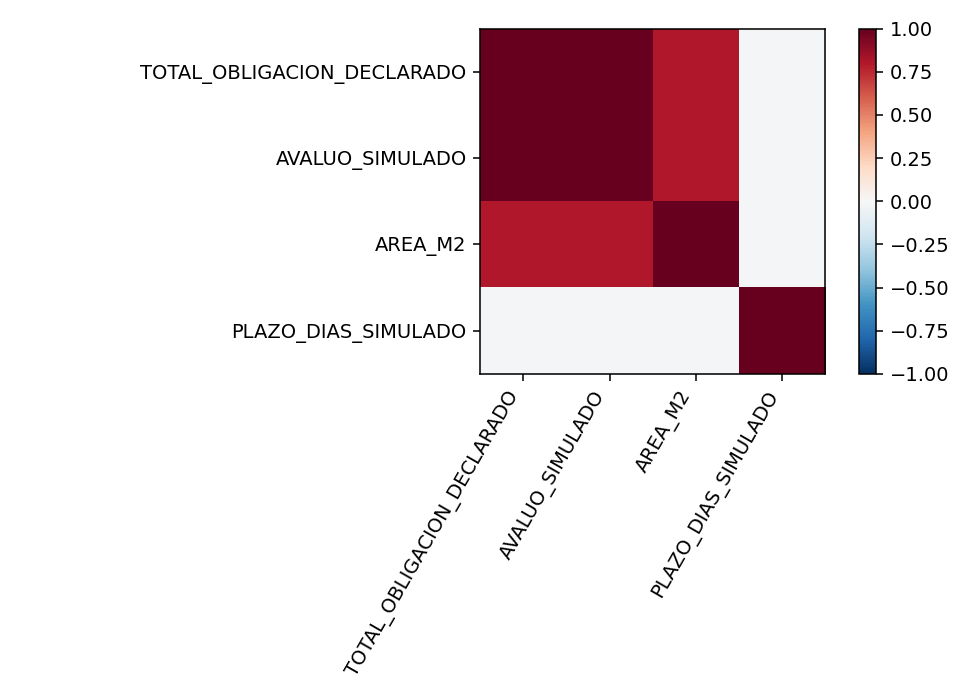

In [4]:
for name in ['distribuciones','outliers','correlaciones']:
    display(Image(filename=str(ROOT / 'docs/eda' / f'{name}.png')))

## Interpretacion
Los tres hallazgos cuantificados anteriores justifican log1p(importe), imputacion en CV y evitar avaluo/importe redundantes. Spearman describe asociaciones monotonicamente y no causalidad; Z-score es diagnostico y no supone normalidad ni elimina filas. La distribucion global del manifiesto es control de generacion; ninguna decision usa desempeno del hold-out.